# Credit Default Risk: A Cost-Aware Model for Loan Screening

**How much money does a 76-AUC model actually save a lender?**

### The Business Problem

A mid-size lender reviews ~50,000 loan applications per year. Historically
they approve everyone above a fixed credit-score cutoff, and 11.6% of
approved loans default. Each default costs roughly **$10,000** in lost
principal; each rejected good applicant costs roughly **$500** in foregone
profit.

The question this notebook answers: *Can a model reduce total expected loss,
and by how much?* Accuracy, ROC AUC, and F1 are intermediate signals — the
deliverable is a dollar figure and a decision rule.

**Dataset:** Kaggle `nikhil1e9/loan-default` (255,347 rows x 18 columns).

**Roadmap:** See the project `README.md` for the full story. Part 2 (`02_extensions.ipynb`) stress-tests the decision rule: cost sensitivity, review capacity, fairness and drift.

*Educational project. Not a lending decision system.*

## Phase 01 - Setup and load

In [1]:
import warnings
warnings.filterwarnings('ignore')

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

pd.set_option('display.max_columns', 50)
sns.set_theme(style='whitegrid', palette='deep')

# ---- Load the dataset -------------------------------------------------------
# 1) Use Loan_default.csv if it is already next to the notebook (or in a known spot).
# 2) Otherwise, in Google Colab, open an "Upload file" button to pick the CSV.
# 3) Otherwise (local Jupyter / VS Code), ask for the file's full path.
CSV_NAME = 'Loan_default.csv'
candidates = [
    CSV_NAME,
    os.path.join('..', 'data', CSV_NAME),          # repo layout: notebooks/ next to data/
    os.path.join('/content', CSV_NAME),
    os.path.join('/kaggle/input/loan-default', CSV_NAME),
    os.path.expanduser(os.path.join('~/Downloads', CSV_NAME)),
]
DATA_PATH = next((c for c in candidates if os.path.exists(c)), None)

if DATA_PATH is None:
    try:
        from google.colab import files          # only exists in Colab
        IN_COLAB = True
    except ImportError:
        IN_COLAB = False

    if IN_COLAB:
        print(f'Please choose {CSV_NAME} in the upload box below...')
        uploaded = files.upload()                # shows the "Choose Files" button
        csvs = [name for name in uploaded if name.lower().endswith('.csv')]
        if not csvs:
            raise FileNotFoundError('No CSV file was uploaded. Re-run this cell and choose Loan_default.csv.')
        DATA_PATH = csvs[0]                       # Colab saves it in the current folder
    else:
        path = input(f'{CSV_NAME} not found. Paste the full path to the CSV file: ').strip().strip('"\'')
        if not path or not os.path.exists(path):
            raise FileNotFoundError(f'Could not find a file at: {path!r}')
        DATA_PATH = path

print(f'Loading dataset from: {DATA_PATH}')
df = pd.read_csv(DATA_PATH)
print('Dataset loaded successfully!')
print(df.shape)
df.head()

Please choose Loan_default.csv in the upload box below...


Saving Loan_default.csv to Loan_default.csv
Loading dataset from: Loan_default.csv
Dataset loaded successfully!
(255347, 18)


,LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,I38PQUQS96,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,Yes,Yes,Other,Yes,0
1,HPSK72WA7R,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,No,No,Other,Yes,0
2,C1OZ6DPJ8Y,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,Yes,Yes,Auto,No,1
3,V2KKSFM3UN,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,No,No,Business,No,0
4,EY08JDHTZP,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,No,Yes,Auto,No,0


## Phase 02 - Meet the data

The target is binary: `Default in {0, 1}`. We have 9 numeric and 7 categorical features, plus an ID column we will drop.

In [2]:
df.info()
print()
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 255347 entries, 0 to 255346
Data columns (total 18 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   LoanID          255347 non-null  object 
 1   Age             255347 non-null  int64  
 2   Income          255347 non-null  int64  
 3   LoanAmount      255347 non-null  int64  
 4   CreditScore     255347 non-null  int64  
 5   MonthsEmployed  255347 non-null  int64  
 6   NumCreditLines  255347 non-null  int64  
 7   InterestRate    255347 non-null  float64
 8   LoanTerm        255347 non-null  int64  
 9   DTIRatio        255347 non-null  float64
 10  Education       255347 non-null  object 
 11  EmploymentType  255347 non-null  object 
 12  MaritalStatus   255347 non-null  object 
 13  HasMortgage     255347 non-null  object 
 14  HasDependents   255347 non-null  object 
 15  LoanPurpose     255347 non-null  object 
 16  HasCoSigner     255347 non-null  object 
 17  Default   

,count,mean,std,min,25%,50%,75%,max
Age,255347.0,43.498306,14.990258,18.0,31.00,43.00,56.00,69.0
Income,255347.0,82499.304597,38963.013729,15000.0,48825.50,82466.00,116219.00,149999.0
LoanAmount,255347.0,127578.865512,70840.706142,5000.0,66156.00,127556.00,188985.00,249999.0
CreditScore,255347.0,574.264346,158.903867,300.0,437.00,574.00,712.00,849.0
MonthsEmployed,255347.0,59.541976,34.643376,0.0,30.00,60.00,90.00,119.0
NumCreditLines,255347.0,2.501036,1.117018,1.0,2.00,2.00,3.00,4.0
InterestRate,255347.0,13.492773,6.636443,2.0,7.77,13.46,19.25,25.0
LoanTerm,255347.0,36.025894,16.969330,12.0,24.00,36.00,48.00,60.0
DTIRatio,255347.0,0.500212,0.230917,0.1,0.30,0.50,0.70,0.9
Default,255347.0,0.116128,0.320379,0.0,0.00,0.00,0.00,1.0


In [3]:
print('Missing values:')
print(df.isna().sum().sum(), 'total nulls')
print()
print('Class balance:')
print(df['Default'].value_counts(normalize=True).round(4))

TARGET = 'Default'
DROP   = ['LoanID']

NUM_COLS = ['Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed',
            'NumCreditLines', 'InterestRate', 'LoanTerm', 'DTIRatio']
CAT_COLS = ['Education', 'EmploymentType', 'MaritalStatus', 'HasMortgage',
            'HasDependents', 'LoanPurpose', 'HasCoSigner']

assert set(NUM_COLS + CAT_COLS + DROP + [TARGET]) == set(df.columns)
print(f'{len(NUM_COLS)} numeric, {len(CAT_COLS)} categorical')

Missing values:
0 total nulls

Class balance:
Default
0    0.8839
1    0.1161
Name: proportion, dtype: float64
9 numeric, 7 categorical


## Phase 03 - Explore (EDA)

**Data-integrity note:** Every numeric feature is *uniformly distributed* -
this is a strong tell that the dataset is synthetic. Expect a low signal ceiling
(~0.76 ROC AUC) and don't chase model complexity.

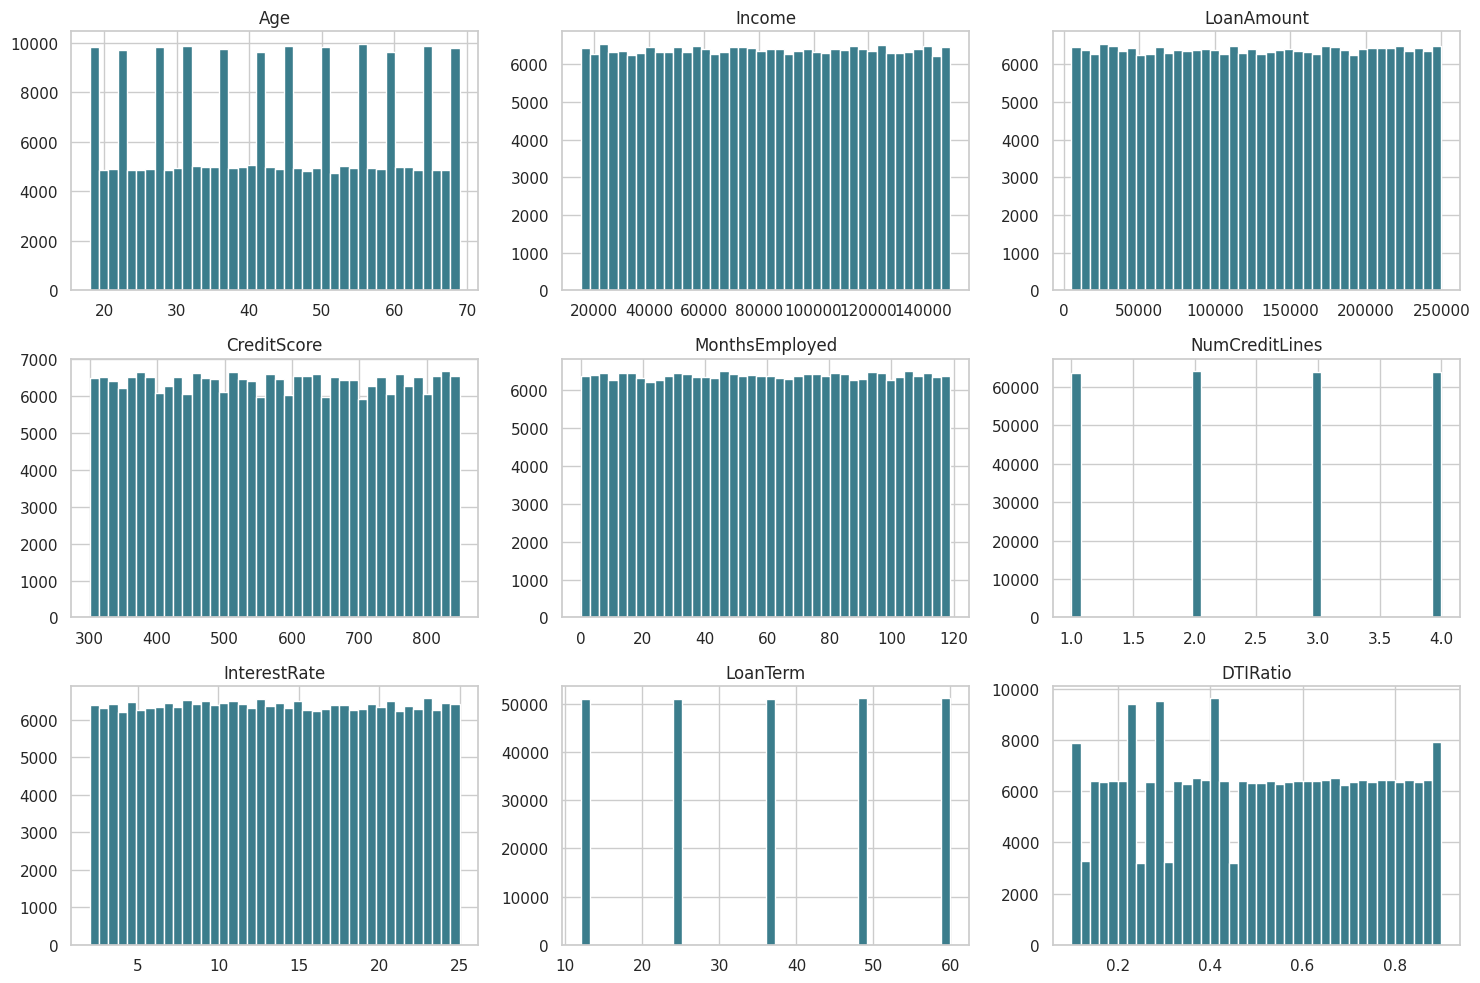

In [4]:
df[NUM_COLS].hist(figsize=(15, 10), bins=40, color='#3b7d8c', edgecolor='white')
plt.tight_layout()
plt.show()

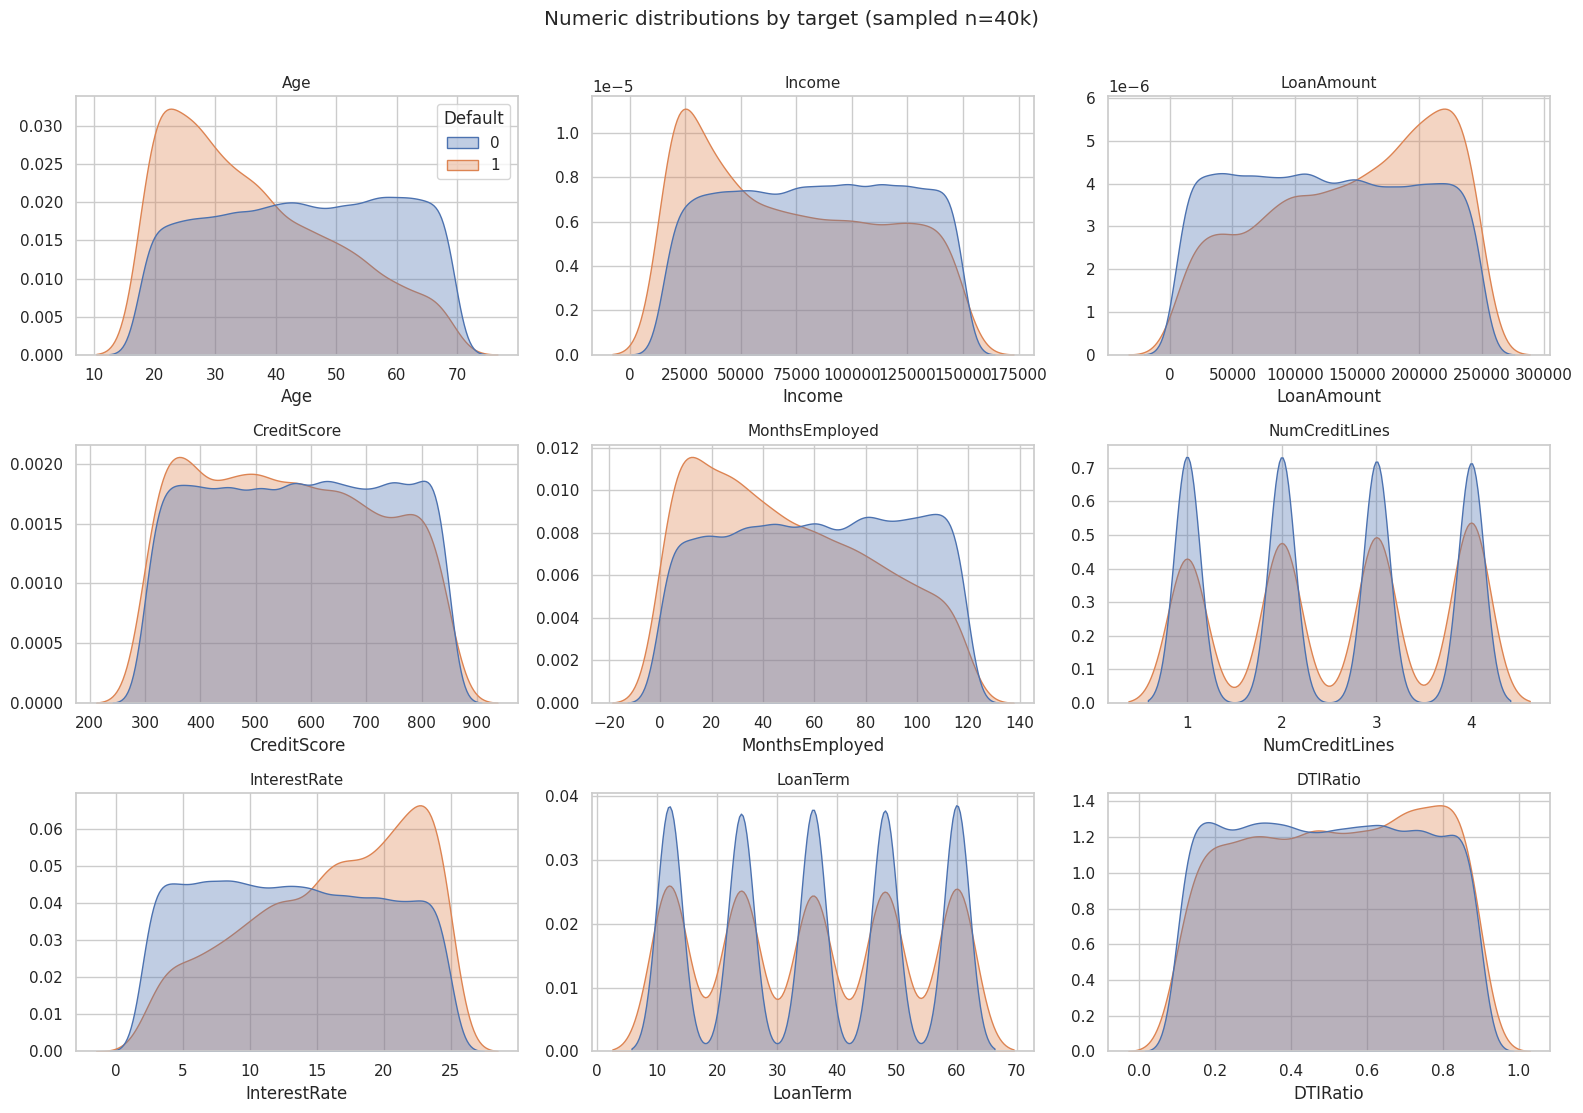

In [5]:
# Sampled KDE plots for speed. Never sample for modelling.
d = df.sample(40_000, random_state=RANDOM_STATE)

fig, axes = plt.subplots(3, 3, figsize=(16, 11))
for ax, col in zip(axes.ravel(), NUM_COLS):
    sns.kdeplot(data=d, x=col, hue=TARGET, common_norm=False,
                fill=True, alpha=.35, ax=ax, legend=(col == NUM_COLS[0]))
    ax.set_title(col, fontsize=11)
    ax.set_ylabel('')
plt.suptitle('Numeric distributions by target (sampled n=40k)', y=1.01)
plt.tight_layout()
plt.show()

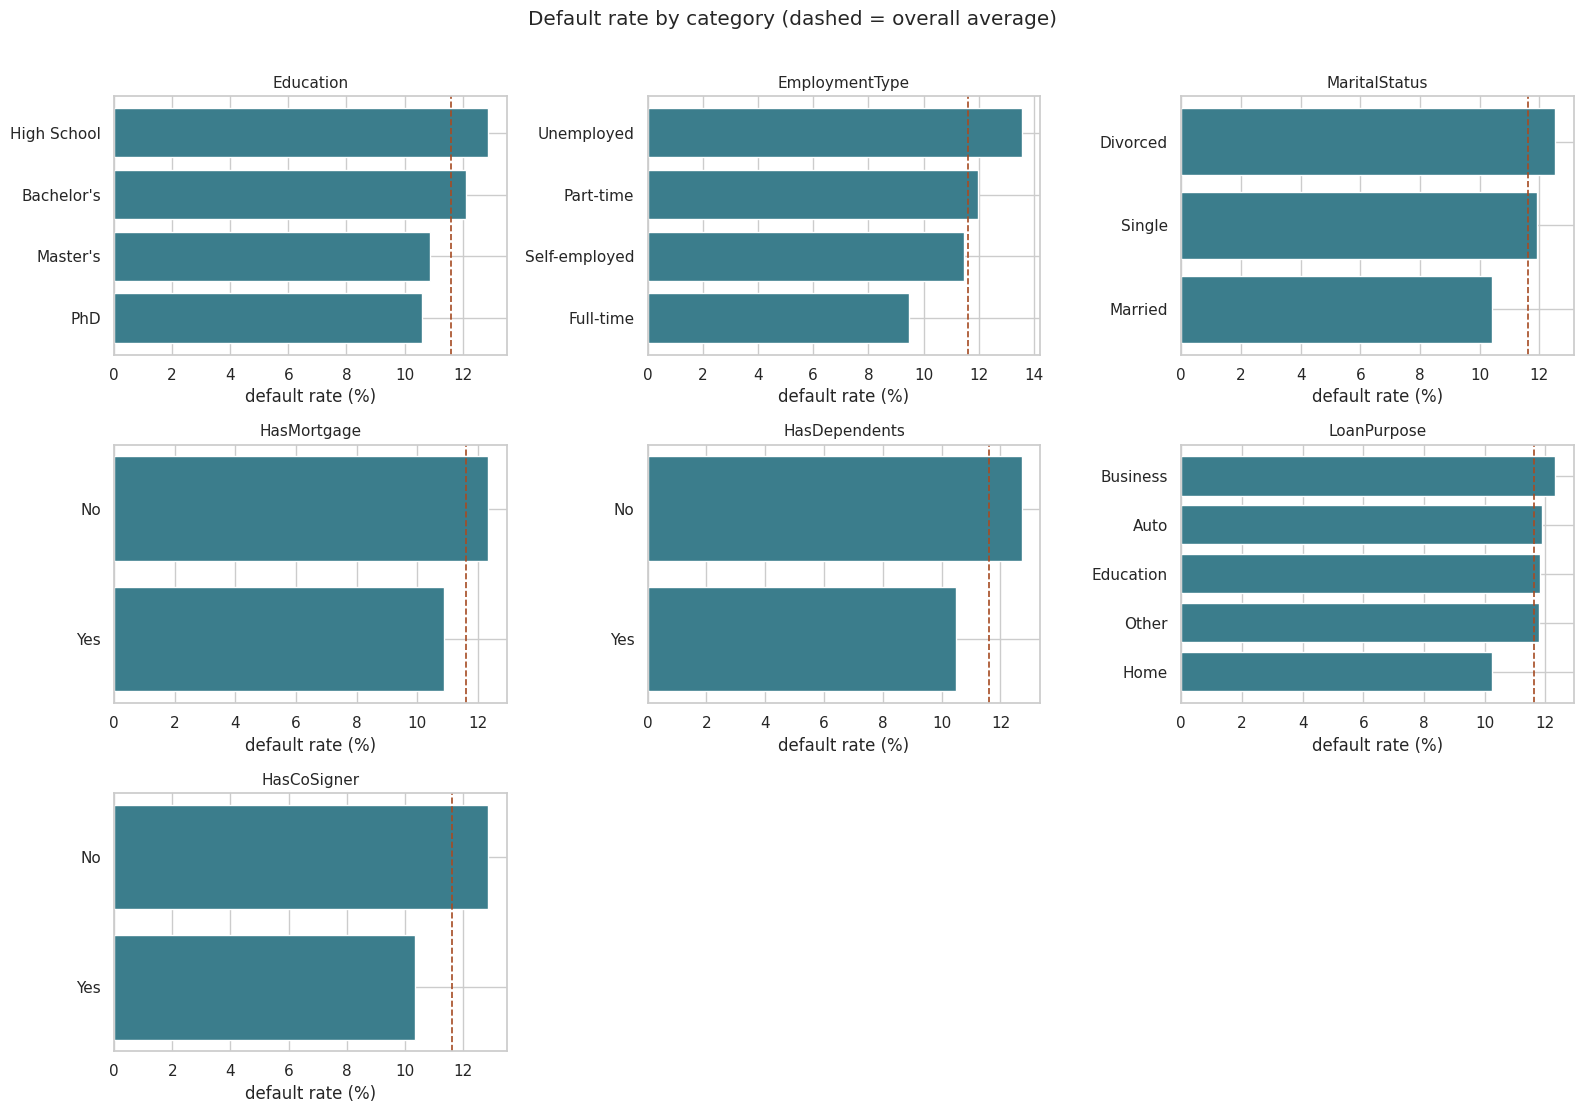

In [6]:
fig, axes = plt.subplots(3, 3, figsize=(16, 11))
overall = df[TARGET].mean()

for ax, col in zip(axes.ravel(), CAT_COLS):
    rates = df.groupby(col)[TARGET].mean().sort_values()
    ax.barh(rates.index.astype(str), rates.values * 100, color='#3b7d8c')
    ax.axvline(overall * 100, color='#a64b23', ls='--', lw=1.2)
    ax.set_title(col, fontsize=11)
    ax.set_xlabel('default rate (%)')

for ax in axes.ravel()[len(CAT_COLS):]:
    ax.set_visible(False)

fig.suptitle('Default rate by category (dashed = overall average)', y=1.01)
plt.tight_layout()
plt.show()

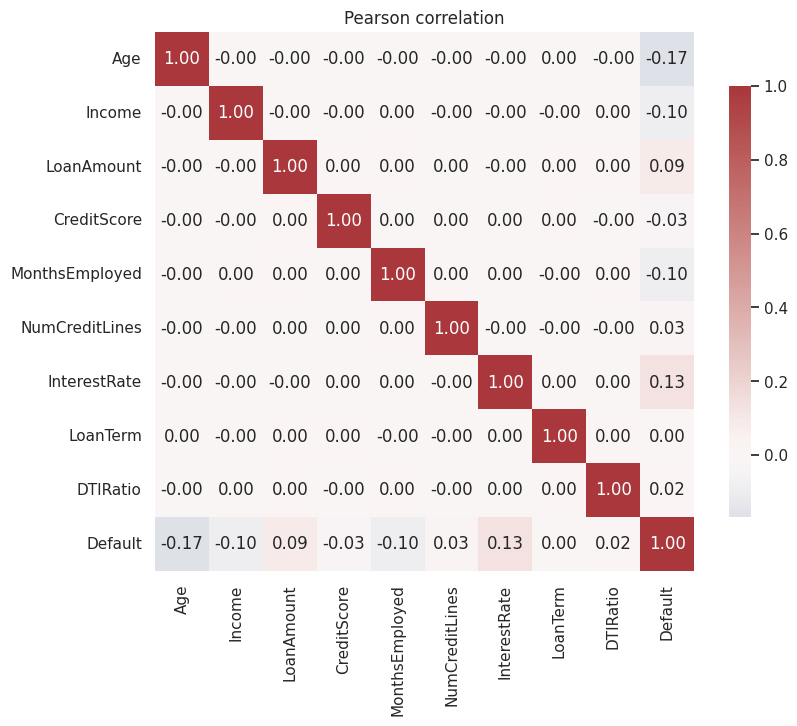

Age              -0.167783
InterestRate      0.131273
Income           -0.099119
MonthsEmployed   -0.097374
LoanAmount        0.086659
CreditScore      -0.034166
NumCreditLines    0.028330
DTIRatio          0.019236
LoanTerm          0.000545
Name: Default, dtype: float64


In [7]:
corr = df[NUM_COLS + [TARGET]].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='vlag', center=0,
            square=True, cbar_kws={'shrink': .8})
plt.title('Pearson correlation')
plt.show()

print(corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False))

### Your turn - write your prediction here before modelling

Which three features will matter most?

**Prediction (made from the EDA above, before any model was fit):**

1. **Age** - the strongest correlation with `Default` (about -0.17); younger applicants default more.
2. **InterestRate** - the strongest positive correlation (about +0.13). Lenders charge riskier borrowers more, so the rate already carries risk information.
3. **Income** - negative correlation (about -0.10); lower income means less room to absorb repayments.

*Expected surprise:* `CreditScore` should be a top feature in real lending data, but here it correlates only weakly (about -0.03). We will check this in Phase 11.

## Phase 04 - Split before you touch anything

Stratified split preserves the 11.6% default rate in both partitions. Everything downstream of this point must only see `X_train`.

In [8]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=[TARGET] + DROP)
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

print(X_train.shape, X_test.shape)
print(f'train default rate {y_train.mean():.4f} | test default rate {y_test.mean():.4f}')

(204277, 16) (51070, 16)
train default rate 0.1161 | test default rate 0.1161


## Phase 05 - Preprocessing pipeline

StandardScaler for numeric features, one-hot encoding for categoricals. Everything wrapped in a `Pipeline` so no statistic ever leaks from test into training.

In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocess = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), NUM_COLS),
        ('cat', OneHotEncoder(handle_unknown='ignore',
                              drop='if_binary',
                              sparse_output=False), CAT_COLS),
    ],
    remainder='drop',
    verbose_feature_names_out=True,
)

sample = preprocess.fit_transform(X_train)
print('shape after preprocessing:', sample.shape)
print('first 12 feature names:', list(preprocess.get_feature_names_out())[:12])

shape after preprocessing: (204277, 28)
first 12 feature names: ['num__Age', 'num__Income', 'num__LoanAmount', 'num__CreditScore', 'num__MonthsEmployed', 'num__NumCreditLines', 'num__InterestRate', 'num__LoanTerm', 'num__DTIRatio', "cat__Education_Bachelor's", 'cat__Education_High School', "cat__Education_Master's"]


## Phase 06 - First models

Baseline first. Then logistic regression. Both will land near 0.88 accuracy - which is exactly what a model that always predicts *repaid* scores. This is why accuracy is the wrong metric here.

In [10]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

dummy = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
print(f'Dummy accuracy: {accuracy_score(y_test, dummy.predict(X_test)):.4f}')

logreg = Pipeline([
    ('prep',  preprocess),
    ('model', LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
])
logreg.fit(X_train, y_train)
print(f'Logistic regression accuracy: {accuracy_score(y_test, logreg.predict(X_test)):.4f}')

Dummy accuracy: 0.8839
Logistic regression accuracy: 0.8853


## Phase 07 - Decision-relevant metrics

Replace accuracy with ROC AUC, PR AUC, and a confusion matrix. Also visualize the ROC and PR curves - the shapes tell you where in the threshold space the model is useful.

===== Logistic regression  (threshold=0.500) =====
              precision    recall  f1-score   support

      repaid      0.887     0.997     0.939     45139
   defaulted      0.610     0.034     0.065      5931

    accuracy                          0.885     51070
   macro avg      0.749     0.516     0.502     51070
weighted avg      0.855     0.885     0.837     51070

ROC AUC : 0.7531
PR  AUC : 0.3116   (a random model scores 0.1161)


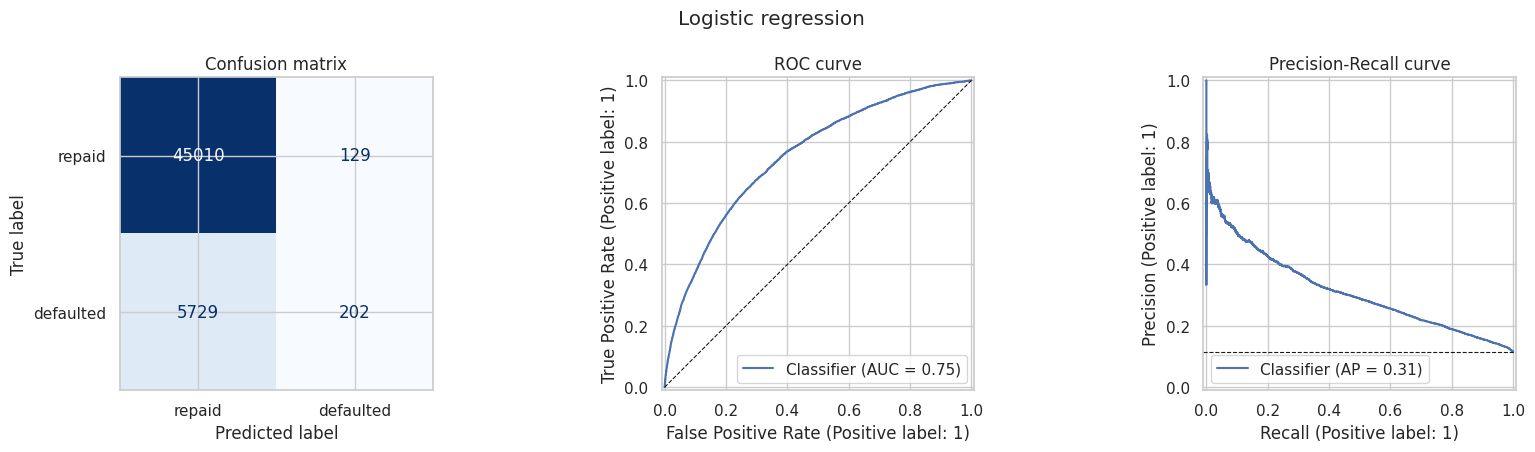

In [11]:
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_auc_score,
                             average_precision_score, RocCurveDisplay,
                             PrecisionRecallDisplay, f1_score)

def evaluate(model, X_te, y_te, name='model', threshold=0.5):
    """Score a fitted classifier the way an imbalanced problem demands."""
    proba = model.predict_proba(X_te)[:, 1]
    pred  = (proba >= threshold).astype(int)

    print(f'===== {name}  (threshold={threshold:.3f}) =====')
    print(classification_report(y_te, pred, digits=3,
                                target_names=['repaid', 'defaulted'],
                                zero_division=0))
    print(f'ROC AUC : {roc_auc_score(y_te, proba):.4f}')
    print(f'PR  AUC : {average_precision_score(y_te, proba):.4f}'
          f'   (a random model scores {y_te.mean():.4f})')

    fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
    ConfusionMatrixDisplay(confusion_matrix(y_te, pred, labels=[0, 1]),
                           display_labels=['repaid', 'defaulted']).plot(
                           ax=axes[0], colorbar=False, cmap='Blues')
    axes[0].set_title('Confusion matrix')
    RocCurveDisplay.from_predictions(y_te, proba, ax=axes[1])
    axes[1].plot([0, 1], [0, 1], 'k--', lw=.8)
    axes[1].set_title('ROC curve')
    PrecisionRecallDisplay.from_predictions(y_te, proba, ax=axes[2])
    axes[2].axhline(y_te.mean(), color='k', ls='--', lw=.8)
    axes[2].set_title('Precision-Recall curve')
    plt.suptitle(name)
    plt.tight_layout()
    plt.show()

    return proba

proba_lr = evaluate(logreg, X_test, y_test, 'Logistic regression')

## Phase 08 - Imbalance and threshold

Two steps: (1) rebalance class weights, (2) choose a threshold using out-of-fold predictions so the test set stays untouched.

===== Logistic regression (balanced)  (threshold=0.500) =====
              precision    recall  f1-score   support

      repaid      0.945     0.673     0.786     45139
   defaulted      0.220     0.699     0.334      5931

    accuracy                          0.676     51070
   macro avg      0.582     0.686     0.560     51070
weighted avg      0.860     0.676     0.734     51070

ROC AUC : 0.7532
PR  AUC : 0.3105   (a random model scores 0.1161)


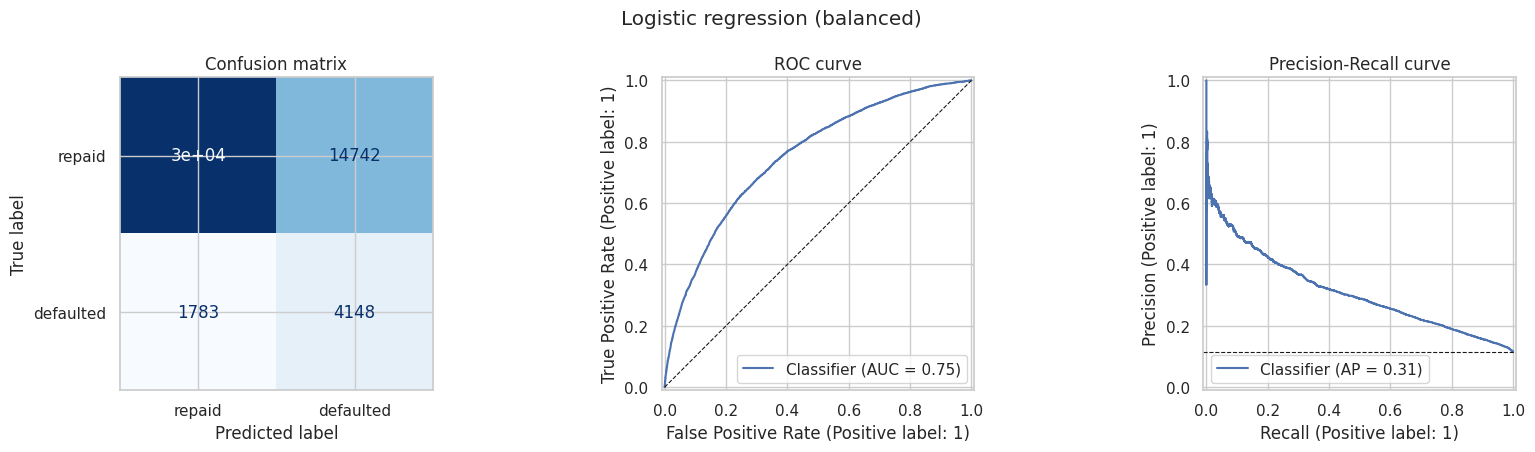

In [12]:
logreg_bal = Pipeline([
    ('prep',  preprocess),
    ('model', LogisticRegression(max_iter=2000, class_weight='balanced',
                                 random_state=RANDOM_STATE)),
])
logreg_bal.fit(X_train, y_train)
proba_bal = evaluate(logreg_bal, X_test, y_test, 'Logistic regression (balanced)')

Best F1 threshold (from training CV): 0.6226
  precision 0.280 | recall 0.486 | F1 0.355
===== Balanced LR @ tuned threshold  (threshold=0.623) =====
              precision    recall  f1-score   support

      repaid      0.928     0.834     0.879     45139
   defaulted      0.288     0.509     0.368      5931

    accuracy                          0.797     51070
   macro avg      0.608     0.672     0.623     51070
weighted avg      0.854     0.797     0.819     51070

ROC AUC : 0.7532
PR  AUC : 0.3105   (a random model scores 0.1161)


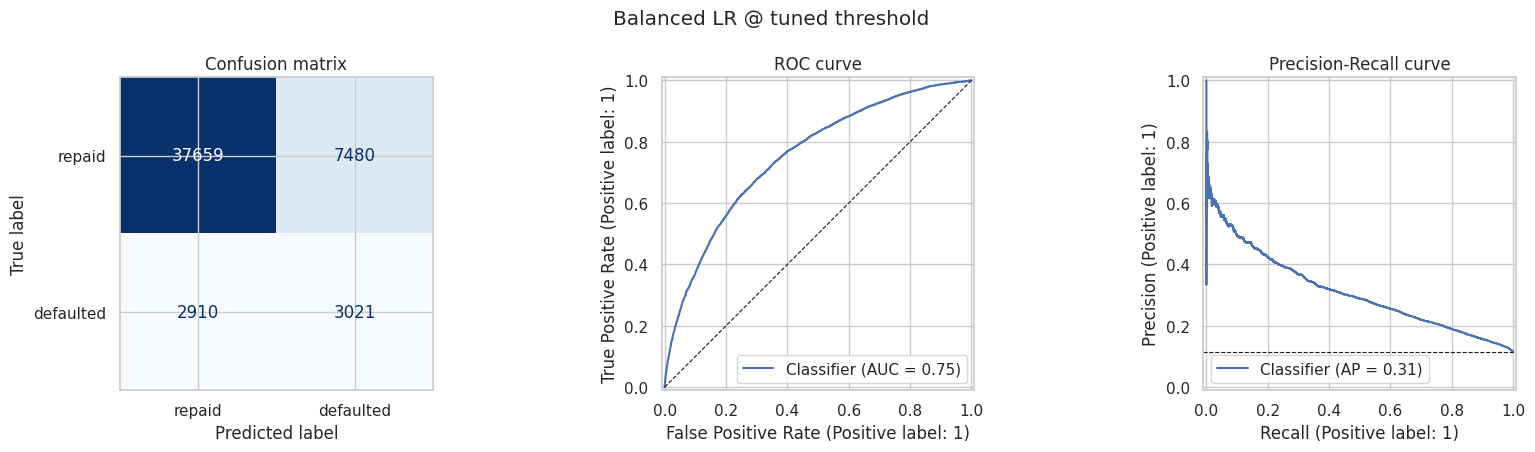

In [13]:
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import precision_recall_curve

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Out-of-fold probabilities: every training row scored by a model that never saw it.
oof = cross_val_predict(logreg_bal, X_train, y_train, cv=cv,
                        method='predict_proba', n_jobs=-1)[:, 1]

prec, rec, thr = precision_recall_curve(y_train, oof)
f1 = 2 * prec * rec / (prec + rec + 1e-12)
best = int(np.nanargmax(f1[:-1]))
BEST_THR = float(thr[best])

print(f'Best F1 threshold (from training CV): {BEST_THR:.4f}')
print(f'  precision {prec[best]:.3f} | recall {rec[best]:.3f} | F1 {f1[best]:.3f}')

proba_bal = evaluate(logreg_bal, X_test, y_test, 'Balanced LR @ tuned threshold',
                     threshold=BEST_THR)

### Cost-sensitive threshold - the metric that actually matters

F1 treats a false negative and a false positive as equally bad. In lending they are not: missing a default is far more expensive than rejecting a good borrower.

We sweep thresholds and pick the one that minimizes expected dollar loss.

Cost-optimal threshold (from training OOF): 0.2800


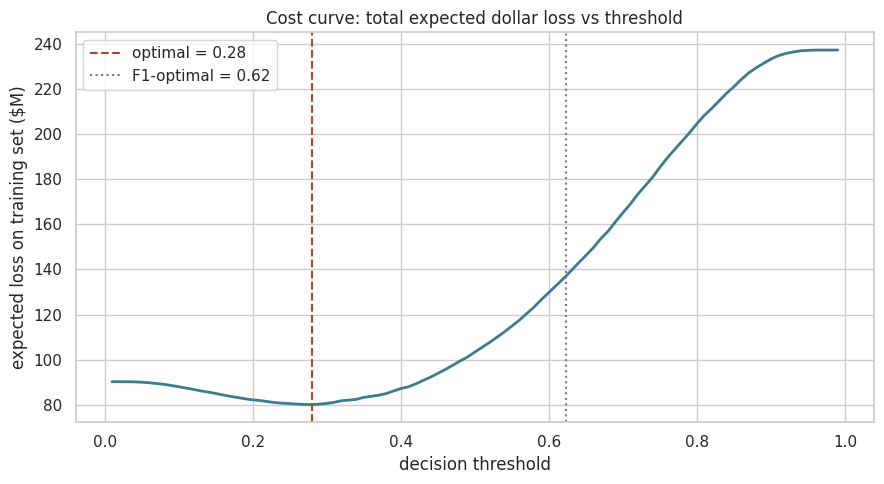


--- Test-set cost comparison ---
Approve everyone (baseline):  $  59,310,000
Model @ F1 threshold:         $  32,840,000
Model @ cost threshold:       $  20,112,000

Savings vs baseline:          $  39,198,000  (66.1%)


In [14]:
# Cost assumptions - state these explicitly. Real deployments replace them
# with calibrated figures from the business. We use ballpark values.
C_FN = 10_000   # cost of approving a loan that defaults (lost principal)
C_FP =    500   # cost of rejecting an applicant who would have repaid

def total_cost(y_true, y_pred, c_fn=C_FN, c_fp=C_FP):
    fn = ((y_true == 1) & (y_pred == 0)).sum()
    fp = ((y_true == 0) & (y_pred == 1)).sum()
    return c_fn * fn + c_fp * fp

# Sweep thresholds on OUT-OF-FOLD probabilities (training set - never test).
thresholds = np.linspace(0.01, 0.99, 99)
costs = np.array([total_cost(y_train.values, (oof >= t).astype(int))
                  for t in thresholds])
COST_THR = float(thresholds[int(np.argmin(costs))])

print(f'Cost-optimal threshold (from training OOF): {COST_THR:.4f}')

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(thresholds, costs / 1e6, lw=2, color='#3b7d8c')
ax.axvline(COST_THR, color='#a64b23', ls='--',
           label=f'optimal = {COST_THR:.2f}')
ax.axvline(BEST_THR, color='#7a7a7a', ls=':',
           label=f'F1-optimal = {BEST_THR:.2f}')
ax.set_xlabel('decision threshold')
ax.set_ylabel('expected loss on training set ($M)')
ax.set_title('Cost curve: total expected dollar loss vs threshold')
ax.legend()
plt.tight_layout()
plt.show()

# Translate to test set
baseline_cost = total_cost(y_test.values, np.zeros_like(y_test.values))
f1_cost       = total_cost(y_test.values, (proba_bal >= BEST_THR).astype(int))
cost_opt_cost = total_cost(y_test.values, (proba_bal >= COST_THR).astype(int))

print(f'\n--- Test-set cost comparison ---')
print(f'Approve everyone (baseline):  ${baseline_cost:>12,}')
print(f'Model @ F1 threshold:         ${f1_cost:>12,}')
print(f'Model @ cost threshold:       ${cost_opt_cost:>12,}')
savings = baseline_cost - cost_opt_cost
print(f'\nSavings vs baseline:          ${savings:>12,}  ({savings/baseline_cost:.1%})')

**Interpretation.** Because false negatives cost 20x false positives, the
cost-optimal threshold sits *below* the F1-optimal threshold - the model
becomes more willing to flag a loan for review. In production this is the
number that would be handed to the credit team.

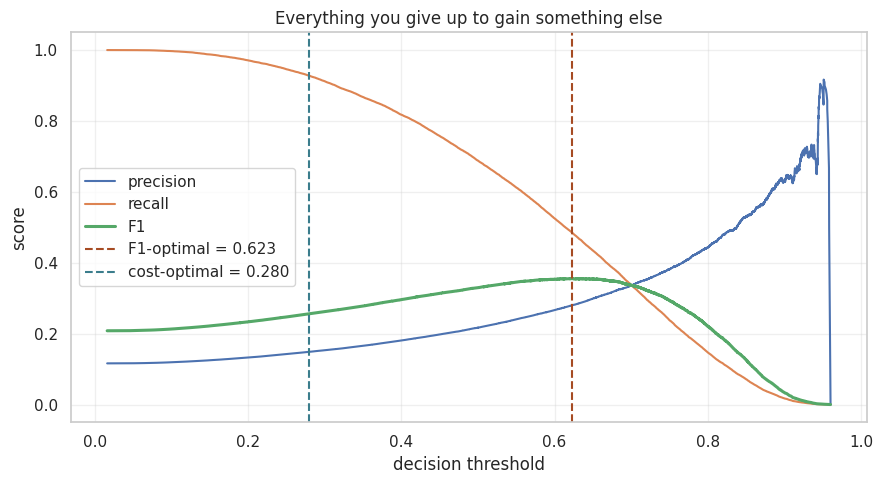

In [15]:
plt.figure(figsize=(9, 5))
plt.plot(thr, prec[:-1], label='precision')
plt.plot(thr, rec[:-1],  label='recall')
plt.plot(thr, f1[:-1],   label='F1', lw=2.2)
plt.axvline(BEST_THR, color='#a64b23', ls='--', label=f'F1-optimal = {BEST_THR:.3f}')
plt.axvline(COST_THR, color='#3b7d8c', ls='--', label=f'cost-optimal = {COST_THR:.3f}')
plt.xlabel('decision threshold'); plt.ylabel('score')
plt.title('Everything you give up to gain something else')
plt.legend(); plt.grid(alpha=.3)
plt.tight_layout()
plt.show()

## Phase 09 - Trees and boosting

We fit a Random Forest and a Histogram Gradient Boosting model with matched
class weighting so the comparison at threshold 0.5 is meaningful.

**Fair threshold comparison.** The 0.28 cost threshold from Phase 08 was tuned on
the *logistic regression's* probabilities. Different models produce differently
scaled scores, so each model gets its **own** cost-optimal threshold, tuned on its
own out-of-fold training predictions in the same way. The test set is still untouched.

===== Random forest  (threshold=0.500) =====
              precision    recall  f1-score   support

      repaid      0.931     0.819     0.872     45139
   defaulted      0.282     0.539     0.370      5931

    accuracy                          0.787     51070
   macro avg      0.606     0.679     0.621     51070
weighted avg      0.856     0.787     0.813     51070

ROC AUC : 0.7557
PR  AUC : 0.3256   (a random model scores 0.1161)


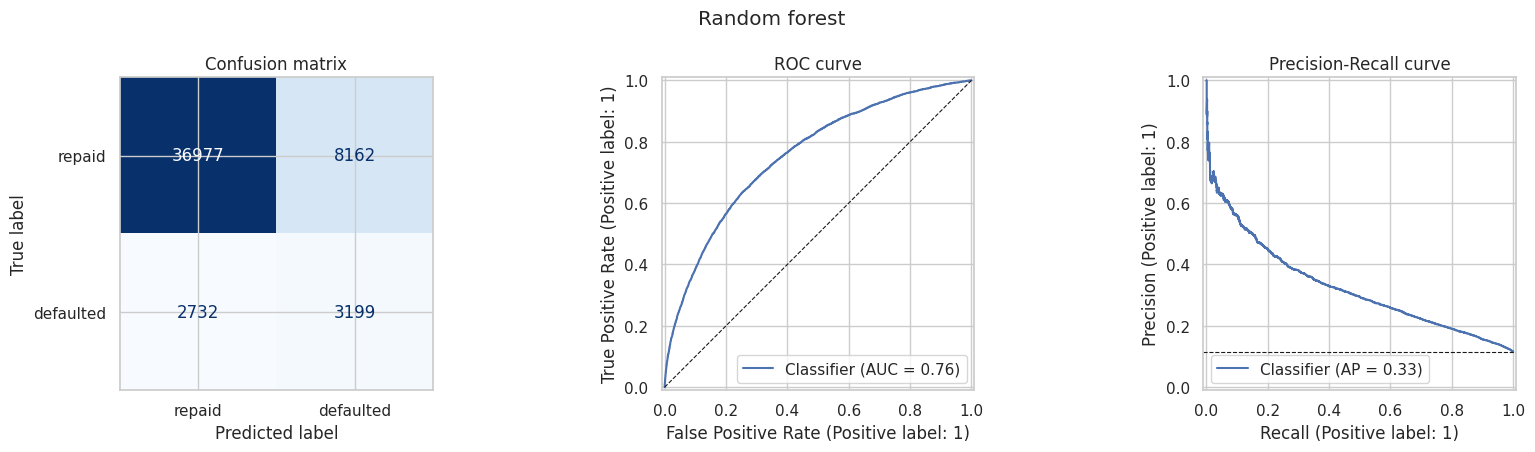

In [16]:
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight

rf = Pipeline([
    ('prep',  preprocess),
    ('model', RandomForestClassifier(
        n_estimators=300, min_samples_leaf=25, max_features='sqrt',
        class_weight='balanced_subsample', n_jobs=-1,
        random_state=RANDOM_STATE)),
])
rf.fit(X_train, y_train)
proba_rf = evaluate(rf, X_test, y_test, 'Random forest')

===== HistGradientBoosting (balanced)  (threshold=0.500) =====
              precision    recall  f1-score   support

      repaid      0.944     0.699     0.803     45139
   defaulted      0.230     0.684     0.344      5931

    accuracy                          0.697     51070
   macro avg      0.587     0.691     0.574     51070
weighted avg      0.861     0.697     0.750     51070

ROC AUC : 0.7573
PR  AUC : 0.3286   (a random model scores 0.1161)


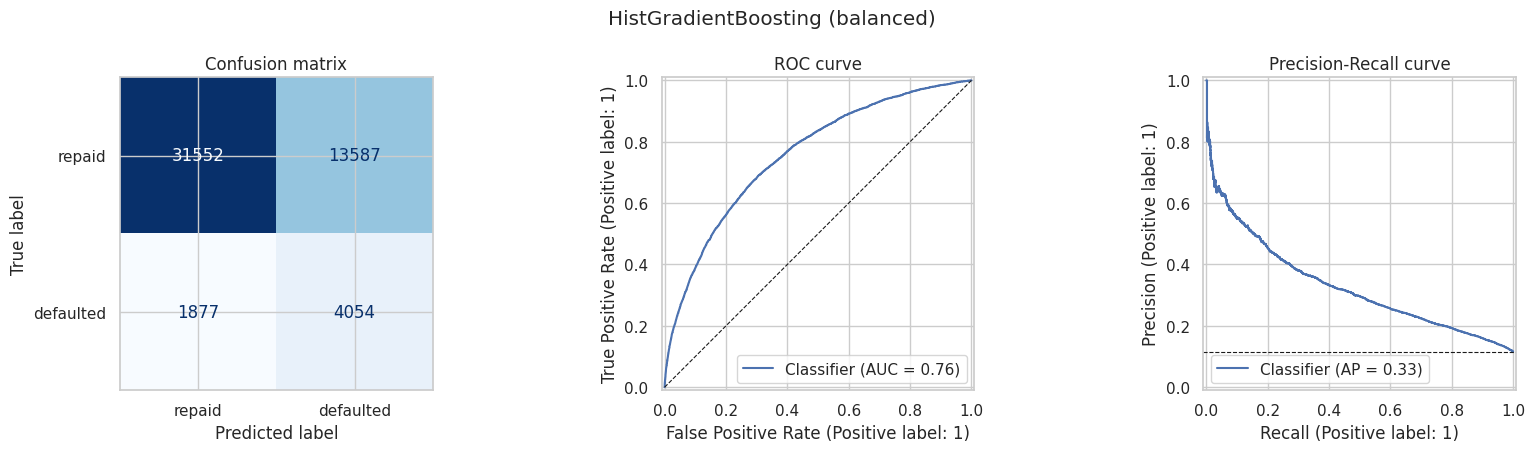

In [17]:
hgb = Pipeline([
    ('prep',  preprocess),
    ('model', HistGradientBoostingClassifier(
        max_iter=400, learning_rate=0.05, max_leaf_nodes=31,
        early_stopping=True, validation_fraction=0.1,
        random_state=RANDOM_STATE)),
])

# HistGB has no class_weight param; supply sample weights instead so
# the comparison against RF (balanced) is apples-to-apples.
sw = compute_sample_weight('balanced', y_train)
hgb.fit(X_train, y_train, model__sample_weight=sw)
proba_hgb = evaluate(hgb, X_test, y_test, 'HistGradientBoosting (balanced)')

### Per-model cost-optimal thresholds

Same recipe as Phase 08: 5-fold out-of-fold probabilities on the training set,
then sweep thresholds and keep the one with the lowest dollar loss. *(The Random
Forest CV takes a few minutes.)*

In [18]:
def cost_optimal_threshold(oof_proba):
    """Threshold that minimises training-set dollar loss on out-of-fold probabilities."""
    c = np.array([total_cost(y_train.values, (oof_proba >= t).astype(int))
                  for t in thresholds])
    i = int(np.argmin(c))
    return float(thresholds[i]), int(c[i])

def oof_proba(model, fit_params=None):
    fit_params = fit_params or {}
    try:   # scikit-learn >= 1.4
        p = cross_val_predict(model, X_train, y_train, cv=cv, method='predict_proba',
                              n_jobs=-1, params=fit_params)
    except TypeError:   # older scikit-learn
        p = cross_val_predict(model, X_train, y_train, cv=cv, method='predict_proba',
                              n_jobs=-1, fit_params=fit_params)
    return p[:, 1]

oof_rf  = oof_proba(rf)
oof_hgb = oof_proba(hgb, {'model__sample_weight': sw})

THR, OOF_COST = {}, {}
for name, p in [('LogReg (balanced)', oof),
                ('RandomForest',      oof_rf),
                ('HistGB (balanced)', oof_hgb)]:
    THR[name], OOF_COST[name] = cost_optimal_threshold(p)
    print(f'{name:<20} cost-optimal threshold {THR[name]:.2f} | '
          f'training OOF cost ${OOF_COST[name]:>12,}')

LogReg (balanced)    cost-optimal threshold 0.28 | training OOF cost $  80,165,500
RandomForest         cost-optimal threshold 0.24 | training OOF cost $  80,474,500
HistGB (balanced)    cost-optimal threshold 0.28 | training OOF cost $  80,302,000


### Model comparison table

One table, all models, side by side. Each tuned model is scored at **its own**
cost-optimal threshold. Plain LogReg is left at 0.5 as an untuned reference.
This is the table that goes into the README.

In [19]:
def score_row(name, model, thr):
    p = model.predict_proba(X_test)[:, 1]
    pred = (p >= thr).astype(int)
    return {
        'Model':        name,
        'Threshold':    round(thr, 2),
        'ROC AUC':      round(roc_auc_score(y_test, p), 4),
        'PR AUC':       round(average_precision_score(y_test, p), 4),
        'F1 @ 0.5':     round(f1_score(y_test, (p >= 0.5).astype(int), zero_division=0), 4),
        'F1 @ cost thr':round(f1_score(y_test, pred, zero_division=0), 4),
        'Test cost $':  int(total_cost(y_test.values, pred)),
    }

summary = pd.DataFrame([
    score_row('Dummy (approve all)',   dummy,      0.5),
    score_row('LogReg @ 0.5 (untuned)', logreg,    0.5),
    score_row('LogReg (balanced)',     logreg_bal, THR['LogReg (balanced)']),
    score_row('RandomForest',          rf,         THR['RandomForest']),
    score_row('HistGB (balanced)',     hgb,        THR['HistGB (balanced)']),
]).set_index('Model')
summary['Savings vs approve-all'] = (summary.loc['Dummy (approve all)', 'Test cost $']
                                     - summary['Test cost $'])
summary

,Threshold,ROC AUC,PR AUC,F1 @ 0.5,F1 @ cost thr,Test cost $,Savings vs approve-all
Model,,,,,,,
Dummy (approve all),0.50,0.5000,0.1161,0.0000,0.0000,59310000,0
LogReg @ 0.5 (untuned),0.50,0.7531,0.3116,0.0645,0.0645,57354500,1955500
LogReg (balanced),0.28,0.7532,0.3105,0.3342,0.2553,20112000,39198000
RandomForest,0.24,0.7557,0.3256,0.3700,0.2580,20149500,39160500
HistGB (balanced),0.28,0.7573,0.3286,0.3440,0.2618,19954000,39356000


## Phase 10 - Calibration

ROC AUC tells us how well the model *ranks* applicants. Calibration tells us
whether a predicted 0.30 actually means a 30% default rate. If we ever price
a loan from model output, calibration matters more than AUC.

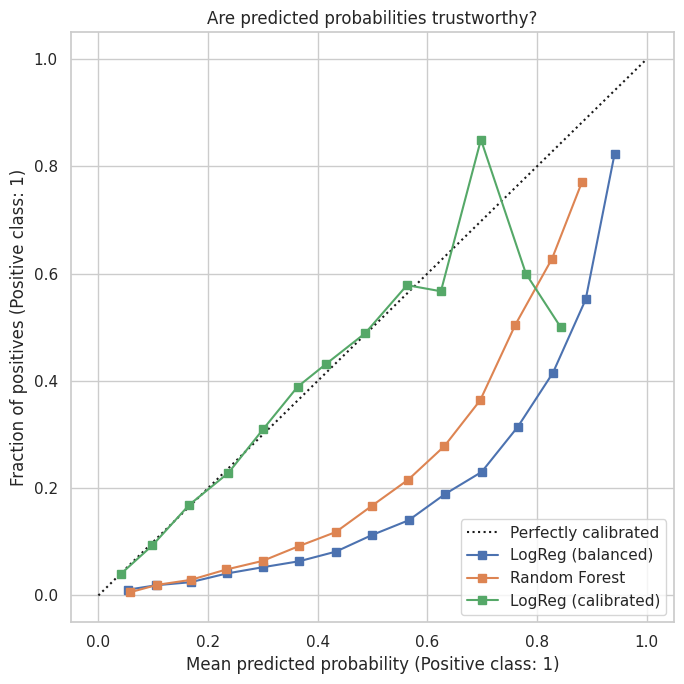

Brier scores (lower is better):
  LogReg balanced: 0.2050
  Random Forest:   0.1579
  Calibrated LR:   0.0918


In [20]:
from sklearn.calibration import CalibrationDisplay, CalibratedClassifierCV

fig, ax = plt.subplots(figsize=(7, 7))

CalibrationDisplay.from_predictions(y_test, proba_bal, n_bins=15, ax=ax,
                                    name='LogReg (balanced)')
CalibrationDisplay.from_predictions(y_test, proba_rf,  n_bins=15, ax=ax,
                                    name='Random Forest')

# Does isotonic calibration on top of balanced LR help?
try:
    cal = CalibratedClassifierCV(estimator=logreg_bal, method='isotonic', cv=3)
except TypeError:
    cal = CalibratedClassifierCV(base_estimator=logreg_bal, method='isotonic', cv=3)

cal.fit(X_train, y_train)
proba_cal = cal.predict_proba(X_test)[:, 1]
CalibrationDisplay.from_predictions(y_test, proba_cal, n_bins=15, ax=ax,
                                    name='LogReg (calibrated)')

ax.set_title('Are predicted probabilities trustworthy?')
plt.tight_layout()
plt.show()

print('Brier scores (lower is better):')
from sklearn.metrics import brier_score_loss
print(f'  LogReg balanced: {brier_score_loss(y_test, proba_bal):.4f}')
print(f'  Random Forest:   {brier_score_loss(y_test, proba_rf):.4f}')
print(f'  Calibrated LR:   {brier_score_loss(y_test, proba_cal):.4f}')

## Phase 11 - Interpretability

Two complementary tools:
- **Permutation importance** (global, model-agnostic): how much does AUC drop when we shuffle a feature?
- **SHAP** (per-prediction + global): how does each feature push each prediction up or down?

Now we close the loop on the Phase 03 prediction.

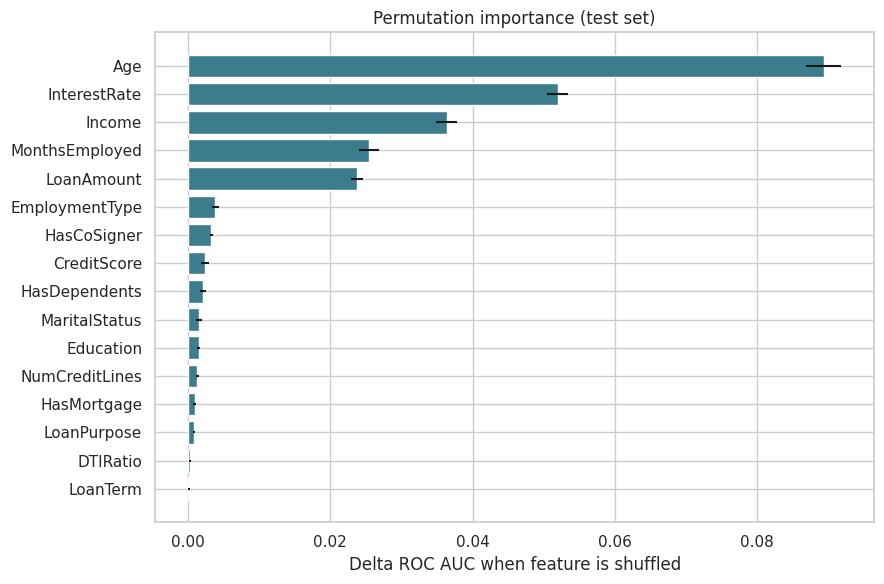

       feature  importance      std
           Age    0.089352 0.002483
  InterestRate    0.051949 0.001437
        Income    0.036371 0.001474
MonthsEmployed    0.025420 0.001379
    LoanAmount    0.023750 0.000838
EmploymentType    0.003855 0.000465
   HasCoSigner    0.003275 0.000229
   CreditScore    0.002383 0.000544
 HasDependents    0.002113 0.000357
 MaritalStatus    0.001524 0.000378
     Education    0.001480 0.000275
NumCreditLines    0.001278 0.000202
   HasMortgage    0.000970 0.000221
   LoanPurpose    0.000832 0.000169
      DTIRatio    0.000279 0.000204
      LoanTerm    0.000126 0.000129


In [21]:
from sklearn.inspection import permutation_importance

result = permutation_importance(
    rf, X_test, y_test,
    n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1, scoring='roc_auc'
)

imp = pd.DataFrame({
    'feature':    X_test.columns,
    'importance': result.importances_mean,
    'std':        result.importances_std,
}).sort_values('importance', ascending=False)

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(imp['feature'][::-1], imp['importance'][::-1],
        xerr=imp['std'][::-1], color='#3b7d8c')
ax.set_xlabel('Delta ROC AUC when feature is shuffled')
ax.set_title('Permutation importance (test set)')
plt.tight_layout()
plt.show()

print(imp.to_string(index=False))

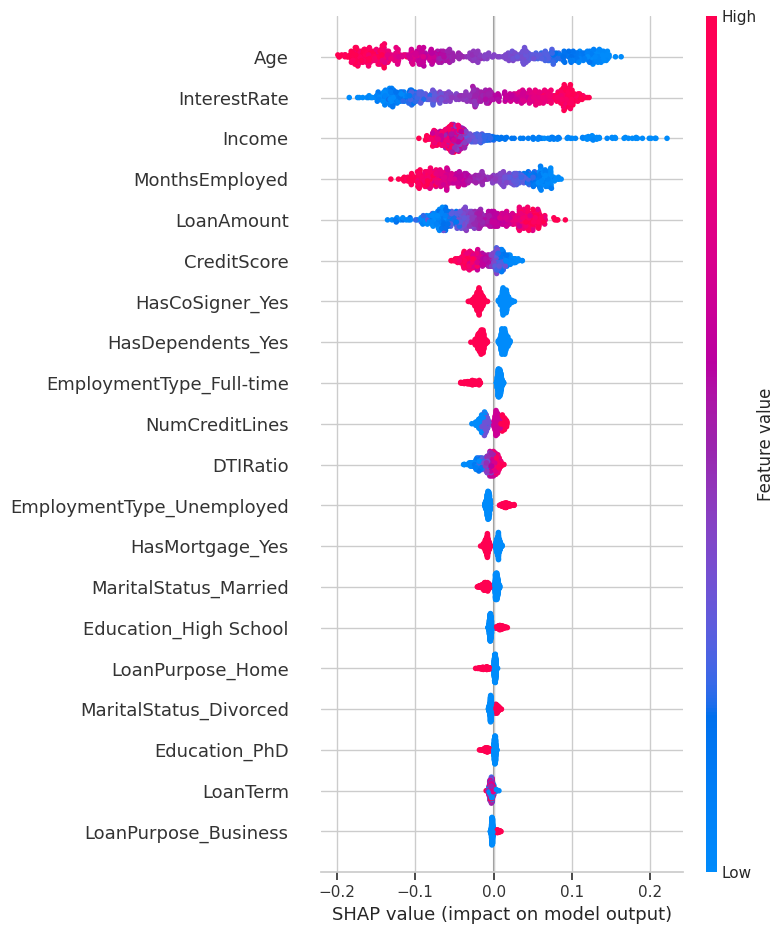

In [22]:
try:
    import shap
except ImportError:
    import subprocess, sys
    try:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'shap'])
        import shap
    except Exception:
        shap = None
        print('SHAP is not installed and could not be installed here - skipping. '
              'Run `pip install shap` and re-run this cell to see the summary plot.')

if shap is not None:

    # Use the fitted RandomForest inside the pipeline.
    explainer = shap.TreeExplainer(rf.named_steps['model'])
    X_test_t = rf.named_steps['prep'].transform(X_test)
    feat_names = rf.named_steps['prep'].get_feature_names_out()

    # Subsample for speed; SHAP is O(n_features * n_samples).
    rng = np.random.default_rng(RANDOM_STATE)
    idx = rng.choice(len(X_test_t), size=min(500, len(X_test_t)), replace=False)
    sv = explainer.shap_values(X_test_t[idx])

    # Handle SHAP output across different versions (list vs 3D ndarray)
    if isinstance(sv, list):
        sv_pos = sv[1]
    elif hasattr(sv, 'ndim') and sv.ndim == 3:
        sv_pos = sv[:, :, 1] if sv.shape[-1] == 2 else sv[1]
    elif hasattr(sv, 'values') and getattr(sv.values, 'ndim', 0) == 3:
        sv_pos = sv.values[:, :, 1]
    else:
        sv_pos = sv

    # Clean prefix from feature names for clear visualization
    clean_feat_names = [f.split('__', 1)[-1] for f in feat_names]

    shap.summary_plot(sv_pos, X_test_t[idx],
                      feature_names=clean_feat_names, show=True)

### Your turn - how did you do?

Compare your Phase 03 prediction against the permutation importance bars
and the SHAP summary. Write 2-3 sentences on what surprised you.

**Result: 3 out of 3.** Permutation importance ranks **Age** (about 0.089 AUC drop),
**InterestRate** (about 0.052) and **Income** (about 0.037) as the top three, just as
predicted, followed by MonthsEmployed and LoanAmount. Together those five features
carry almost all of the signal.

**What surprised me:** **CreditScore** comes 8th (about 0.002), behind EmploymentType
and HasCoSigner. In real lending it is usually the single strongest predictor.
**DTIRatio** and **LoanTerm** contribute almost nothing. This fits the synthetic-data
warning from Phase 03: the generator links default to a handful of variables, so the
model learns the generator's rules, not real credit behaviour.

## Phase 12 - Production handoff

**Choosing the champion.** The model that ships is chosen by **training out-of-fold
cost** (Phase 09), *not* by test cost. Choosing on the test set would turn it into
a second validation set and make the reported savings optimistic. The test set is
only used to report the champion's performance.

The pipeline (preprocessing + model) is persisted as a single artifact so
the same transformations are applied at inference time. A thin wrapper
translates probabilities into decisions using the champion's cost-optimal threshold.

In [23]:
import joblib

MODELS = {'LogReg (balanced)': logreg_bal, 'RandomForest': rf, 'HistGB (balanced)': hgb}
CHAMPION = min(OOF_COST, key=OOF_COST.get)
champ = MODELS[CHAMPION]
proba_champ = champ.predict_proba(X_test)[:, 1]

print('Training OOF cost by model (lower is better):')
for k, v in sorted(OOF_COST.items(), key=lambda kv: kv[1]):
    gap = (v - OOF_COST[CHAMPION]) / OOF_COST[CHAMPION]
    print(f'  {k:<20} ${v:>12,}   (+{gap:.1%} vs champion)')
print(f'\nChampion: {CHAMPION} @ threshold {THR[CHAMPION]:.2f}')

joblib.dump({
    'pipeline':   champ,
    'model_name': CHAMPION,
    'threshold':  THR[CHAMPION],
    'cost_fn':    C_FN,
    'cost_fp':    C_FP,
    'metadata':   {
        'trained_on':    'synthetic loan default dataset',
        'n_train':       len(X_train),
        'default_rate':  float(y_train.mean()),
        'oof_cost_train':OOF_COST[CHAMPION],
        'roc_auc_test':  float(roc_auc_score(y_test, proba_champ)),
        'cost_test':     int(total_cost(y_test.values,
                                        (proba_champ >= THR[CHAMPION]).astype(int))),
    },
}, 'loan_default_v1.joblib')

print('Saved loan_default_v1.joblib')

def score_applicants(df: pd.DataFrame) -> pd.DataFrame:
    """Return default probability and recommended decision per applicant."""
    artifact = joblib.load('loan_default_v1.joblib')
    p = artifact['pipeline'].predict_proba(df)[:, 1]
    return pd.DataFrame({
        'default_probability': p.round(4),
        'decision': np.where(p >= artifact['threshold'], 'REVIEW', 'APPROVE'),
    }, index=df.index)

# Smoke test on a slice of the test set
score_applicants(X_test.head(5))

Training OOF cost by model (lower is better):
  LogReg (balanced)    $  80,165,500   (+0.0% vs champion)
  HistGB (balanced)    $  80,302,000   (+0.2% vs champion)
  RandomForest         $  80,474,500   (+0.4% vs champion)

Champion: LogReg (balanced) @ threshold 0.28
Saved loan_default_v1.joblib


,default_probability,decision
211648,0.1863,APPROVE
201101,0.1400,APPROVE
140423,0.3785,REVIEW
204530,0.5695,REVIEW
166481,0.4079,REVIEW


**Reading the champion choice.** Balanced LogReg wins on training cost (threshold 0.28).
HistGB is only about **0.2%** behind and RandomForest about 0.4%, which is within
run-to-run noise. Small differences between scikit-learn versions can change the
order. On the test set HistGB is about $0.16M cheaper out of $59M, but we do not
choose on the test set. LogReg winning is also a good outcome: its coefficients are
easy to read and it is easier to give adverse-action reasons to regulators.


### What production would need (not built here)

- **Monitoring:** population stability index (PSI) on input distributions, Gini/AUC tracking over time, decision-rate tracking.
- **Drift detection:** alert on label drift (default rate) and covariate drift (feature distributions).
- **Fairness audit:** disparate impact ratio by `Age`, `MaritalStatus`, `HasDependents` (protected-class proxies in many jurisdictions).
- **Human-in-the-loop:** all `REVIEW` decisions routed to an analyst; never fully automated.
- **Cost calibration:** `C_FN` and `C_FP` should be re-estimated quarterly from actual loss data.
- **Retraining cadence:** quarterly or on drift trigger, with a champion/challenger framework.

## Limitations

1. **Synthetic data.** Every numeric feature is uniformly distributed, which
   is not how real applicant data behaves. Reported AUCs (~0.76) likely
   *overstate* what a real deployment would achieve on real credit data.
2. **No fairness audit.** `Age`, `MaritalStatus`, and `HasDependents` are
   protected-class proxies in many jurisdictions. A production model would
   require disparate-impact testing (e.g., 4/5ths rule) before deployment.
3. **Costs are assumptions.** `C_FN=10,000` and `C_FP=500` are placeholders.
   The chosen threshold is only as good as these estimates - a sensitivity
   analysis over cost ratios should accompany any real deployment.
4. **No temporal validation.** Data is treated as i.i.d. Real credit data
   drifts; a time-based split would give a more honest estimate of
   out-of-sample performance.
5. **No reject-inference.** The dataset only contains *approved* loans.
   Performance on the rejected population is unknown (a classic
   sample-selection problem in credit scoring).
6. **`LoanID` leakage.** Other public notebooks on this dataset hit 0.99+ AUC
   by keeping `LoanID` as a feature. We dropped it deliberately; the honest
   ceiling is ~0.76.

---

### Summary of results

Test set: 51,070 applications (20% stratified hold-out). Costs: $10,000 per missed default, $500 per rejected good borrower.

| Metric | Value |
|--------|-------|
| Champion model | LogReg (balanced), chosen on training OOF cost |
| ROC AUC (test) | 0.753 (best model, HistGB: 0.757) |
| PR AUC (test)  | 0.311 (random baseline 0.116) |
| Cost-optimal threshold | 0.28 (HistGB 0.28, RandomForest 0.24) |
| Test cost: approve everyone | $59.31M |
| Test cost: champion @ 0.28 | $20.11M |
| **Expected savings vs. approve-everyone** | **$39.20M (66.1%)** |
| Best calibrated model | LogReg (balanced) + isotonic (Brier 0.092 vs 0.205 uncalibrated) |
| Top features | Age, InterestRate, Income |

*Next steps: cost sensitivity sweep, fairness audit, temporal validation, reject-inference.*